# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

Dimitriu Eduard, IASD 2602 Ru

In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
FILE = "Orange_Telecom_Churn_Data.csv"
path = FILE if os.path.exists(FILE) else os.path.join("..", "materials", FILE)
raw = pd.read_csv(path)
raw.head()

,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [2]:
cat_cols = raw.select_dtypes(include=["object", "string", "bool"]).columns.tolist() + ["area_code"]
card = pd.DataFrame({
    "уникальных": raw[cat_cols].nunique(),
    "доля от числа строк": (raw[cat_cols].nunique() / len(raw)).round(4),
    "статус": ["удалена" if c in ("state", "area_code", "phone_number") else "оставлена" for c in cat_cols],
}).sort_values("уникальных", ascending=False)
print("Строк в наборе:", len(raw))
card

Строк в наборе: 5000


,уникальных,доля от числа строк,статус
phone_number,5000,1.0000,удалена
state,51,0.0102,удалена
area_code,3,0.0006,удалена
intl_plan,2,0.0004,оставлена
voice_mail_plan,2,0.0004,оставлена
churned,2,0.0004,оставлена


In [3]:
# Сколько признаков добавит one-hot кодирование каждой колонки
for c in ["phone_number", "state", "area_code", "intl_plan", "voice_mail_plan"]:
    print(f"{c:16s} -> {raw[c].nunique():5d} бинарных столбцов")
print("Числовых признаков в модели:", raw.select_dtypes("number").shape[1] - 1)

phone_number     ->  5000 бинарных столбцов
state            ->    51 бинарных столбцов
area_code        ->     3 бинарных столбцов
intl_plan        ->     2 бинарных столбцов
voice_mail_plan  ->     2 бинарных столбцов
Числовых признаков в модели: 15


phone_number у каждого клиента свой, 5000 разных значений на 5000 строк. Если сделать ему one-hot, будет 5000 новых столбцов, и нормальные 16 признаков в них просто утонут.

По расстоянию это выглядит так: у двух любых разных клиентов векторы номера отличаются в двух местах, и к квадрату расстояния всегда прибавляется 2. Получается, номер ничего не говорит о том, похожи клиенты или нет, он просто одинаково отодвигает всех друг от друга. Плюс такая матрица почти из одних нулей весит O(n²), и признаков становится больше, чем самих объектов. KNN тогда по сути запоминает клиентов по номеру, а у нового клиента номер всегда новый, так что толку ноль, только переобучение.

state и area_code я тоже выкинул, на отток они почти не влияют. intl_plan и voice_mail_plan там просто yes/no, LabelBinarizer делает из них один столбец 0/1.

In [4]:
from sklearn.preprocessing import LabelBinarizer, MinMaxScaler, StandardScaler

data = raw.drop(columns=["state", "area_code", "phone_number"]).copy()
lb = LabelBinarizer()
for col in ["intl_plan", "voice_mail_plan", "churned"]:
    data[col] = lb.fit_transform(data[col].astype(str)).ravel()

X_raw = data.drop(columns="churned")
y = data["churned"].to_numpy()
X = pd.DataFrame(MinMaxScaler().fit_transform(X_raw), columns=X_raw.columns)
X.describe().T[["min", "max"]].head()

,min,max
account_length,0.0,1.0
intl_plan,0.0,1.0
voice_mail_plan,0.0,1.0
number_vmail_messages,0.0,1.0
total_day_minutes,0.0,1.0


### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [5]:
# Два клиента: стаж различается на 40 дней (16% диапазона), начисления на 30 у.е. (30% диапазона)
a = np.array([100.0, 10.0])   # account_length, total_day_charge
b = np.array([140.0, 40.0])
ranges = np.array([[1, 250], [0, 100]])

d_raw = np.linalg.norm(a - b)
a_s = (a - ranges[:, 0]) / (ranges[:, 1] - ranges[:, 0])
b_s = (b - ranges[:, 0]) / (ranges[:, 1] - ranges[:, 0])
d_scaled = np.linalg.norm(a_s - b_s)

print(f"Без масштабирования: d = {d_raw:.2f}; вклад account_length в d^2 = {(a[0]-b[0])**2 / d_raw**2:.0%}")
print(f"С MinMaxScaler:       d = {d_scaled:.3f}; вклад account_length в d^2 = {(a_s[0]-b_s[0])**2 / d_scaled**2:.0%}")

# Реальные данные: какой признак определяет расстояние без масштабирования
num = raw.select_dtypes("number").drop(columns="area_code")
share = (num.var() / num.var().sum()).sort_values(ascending=False)
print("\nДоля признака в среднем квадрате расстояния без масштабирования (реальные данные):")
print(share.head(5).round(3))

Без масштабирования: d = 50.00; вклад account_length в d^2 = 64%
С MinMaxScaler:       d = 0.340; вклад account_length в d^2 = 22%

Доля признака в среднем квадрате расстояния без масштабирования (реальные данные):
total_day_minutes      0.262
total_eve_minutes      0.231
total_night_minutes    0.230
account_length         0.142
total_night_calls      0.036
dtype: float64


MinMaxScaler:   99% обычных точек лежат в диапазоне шириной 0.052 из [0, 1]
StandardScaler: 99% обычных точек лежат в диапазоне шириной 1.005 (std = 1)


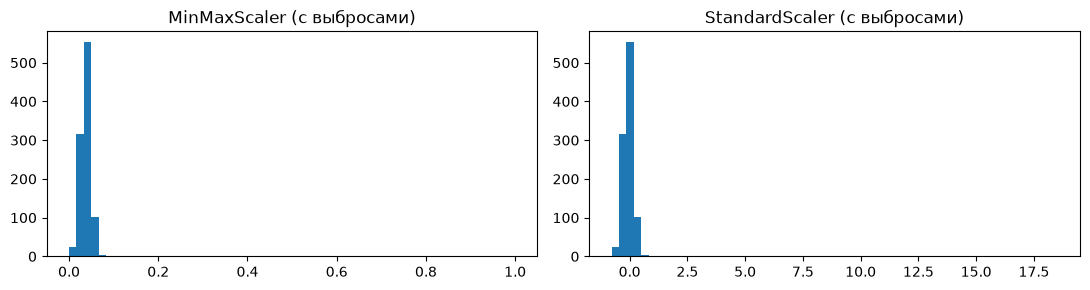

In [6]:
# Влияние выбросов: MinMaxScaler против StandardScaler
rng = np.random.default_rng(RANDOM_STATE)
feature = np.concatenate([rng.normal(30, 5, 995), [300, 320, 350, 400, 500]]).reshape(-1, 1)

mm = MinMaxScaler().fit_transform(feature).ravel()
ss = StandardScaler().fit_transform(feature).ravel()
print(f"MinMaxScaler:   99% обычных точек лежат в диапазоне шириной {np.ptp(np.percentile(mm[:995], [0.5, 99.5])):.3f} из [0, 1]")
print(f"StandardScaler: 99% обычных точек лежат в диапазоне шириной {np.ptp(np.percentile(ss[:995], [0.5, 99.5])):.3f} (std = 1)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(mm, bins=60); axes[0].set_title("MinMaxScaler (с выбросами)")
axes[1].hist(ss, bins=60); axes[1].set_title("StandardScaler (с выбросами)")
plt.tight_layout(); plt.show()

В моём примере клиенты по начислениям отличаются сильнее (на 30% диапазона), чем по стажу (на 16%). Но без масштабирования 64% расстояния даёт account_length, просто потому что числа у него больше. С MinMaxScaler стаж даёт уже только 22%, как и должно быть. На настоящих данных то же самое, без масштабирования всё решают минуты разговоров, у них самый большой разброс, а бинарные признаки вообще ничего не весят.

Если есть выбросы, MinMaxScaler плохо работает: максимум задаёт выброс, и все нормальные значения сжимаются в полоску у нуля, у меня ширина вышла 0.05. StandardScaler от выбросов тоже страдает, они сдвигают среднее и std, но нормальные точки хотя бы остаются разбросанными, ширина около 1. А если выбросов много, лучше взять RobustScaler, он считает по медиане и квартилям.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [7]:
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.default_rng(RANDOM_STATE)
X_syn = rng.random((100_000, 10))
y_syn = rng.integers(0, 2, 100_000)
X_query = X_syn[:5_000]

def bench():
    knn = KNeighborsClassifier(n_neighbors=5, algorithm="kd_tree")
    t0 = time.perf_counter(); knn.fit(X_syn, y_syn); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); knn.predict(X_query); t_pred = time.perf_counter() - t0
    return t_fit, t_pred

fit_stock, pred_stock = bench()
print(f"Стандартный scikit-learn: fit = {fit_stock:.3f} c, predict(5000) = {pred_stock:.3f} c")

try:
    from sklearnex import patch_sklearn, unpatch_sklearn
    patch_sklearn()
    from sklearn.neighbors import KNeighborsClassifier  # переимпорт после патча
    fit_intel, pred_intel = bench()
    print(f"С Intel Extension:        fit = {fit_intel:.3f} c, predict(5000) = {pred_intel:.3f} c")
    print(f"Ускорение predict: x{pred_stock / pred_intel:.1f}")
    unpatch_sklearn()
    from sklearn.neighbors import KNeighborsClassifier
except ImportError:
    print("scikit-learn-intelex не установлен, замер с патчем пропущен")

Стандартный scikit-learn: fit = 0.119 c, predict(5000) = 0.671 c


С Intel Extension:        fit = 0.038 c, predict(5000) = 0.021 c
Ускорение predict: x32.3


Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


С патчем Intel predict на 5000 точках стал примерно в 30 раз быстрее (0.67 с против 0.02 с), fit тоже быстрее, но он и так почти ничего не стоит, KNN на fit только строит индекс.

Как я понял, patch_sklearn() подменяет реализации sklearn, в том числе KNeighborsClassifier, на версии из Intel oneDAL. Поиск соседей там написан на C++, расстояния считаются блоками через векторные инструкции AVX2/AVX-512, то есть за одну инструкцию сразу 8–16 чисел, и всё раскидывается по всем ядрам процессора. Код при этом менять не нужно, меняется только то, что считает внутри. Поэтому самый большой выигрыш как раз на predict, где идёт сам поиск соседей.

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

In [8]:
from sklearn.datasets import make_moons

def minkowski_distance(x, y, p):
    if np.isinf(p):
        return np.max(np.abs(x - y))          # предел p -> inf: расстояние Чебышёва
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

u, v = np.array([0.0, 0.0]), np.array([3.0, 4.0])
for p in [1, 2, 3, 10, np.inf]:
    print(f"p = {p}: d = {minkowski_distance(u, v, p):.4f}")

p = 1: d = 7.0000
p = 2: d = 5.0000
p = 3: d = 4.4979
p = 10: d = 4.0220
p = inf: d = 4.0000


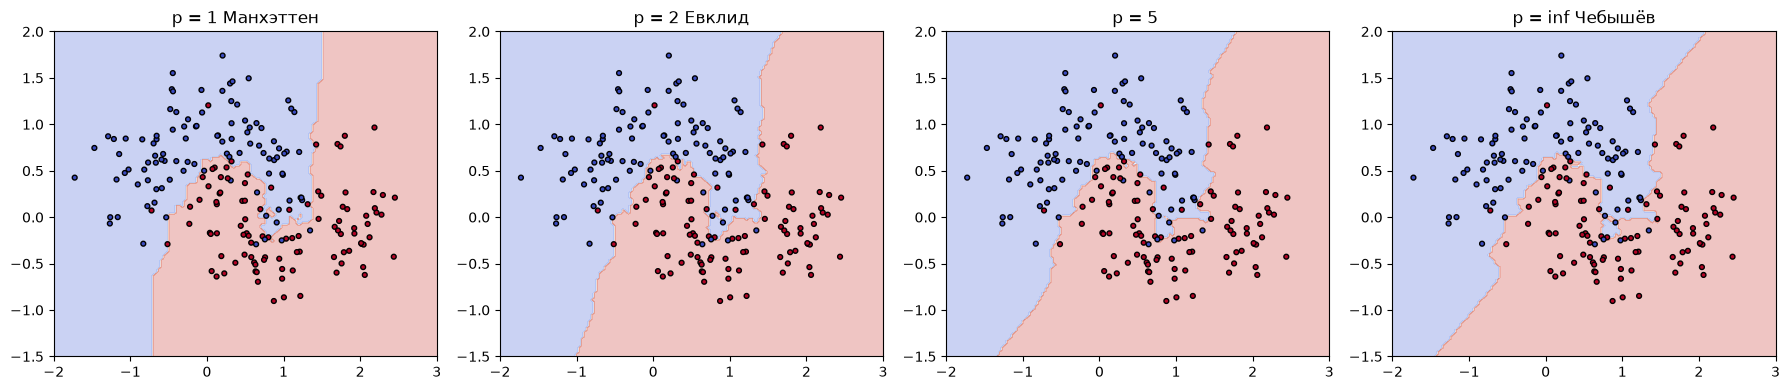

In [9]:
class MinkowskiKNN:
    def __init__(self, k=5, p=2):
        self.k, self.p = k, p
    def fit(self, X, y):
        self.X, self.y = np.asarray(X), np.asarray(y)
        return self
    def predict(self, Xq):
        diff = np.abs(np.asarray(Xq)[:, None, :] - self.X[None, :, :])
        d = diff.max(axis=2) if np.isinf(self.p) else (diff ** self.p).sum(axis=2) ** (1 / self.p)
        idx = np.argsort(d, axis=1)[:, :self.k]
        return (self.y[idx].mean(axis=1) >= 0.5).astype(int)

Xm, ym = make_moons(n_samples=200, noise=0.3, random_state=RANDOM_STATE)
xx, yy = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-1.5, 2, 150))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, p in zip(axes, [1, 2, 5, np.inf]):
    model = MinkowskiKNN(k=7, p=p).fit(Xm, ym)
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.3, cmap="coolwarm")
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=12, edgecolor="k")
    name = {1: "Манхэттен", 2: "Евклид"}.get(p, "Чебышёв" if np.isinf(p) else "")
    ax.set_title(f"p = {p} {name}")
plt.tight_layout(); plt.show()

Для точек (0,0) и (3,4) расстояние с ростом p уменьшается: 7 при p=1, 5 при p=2, а дальше стремится к 4, это и есть max|xᵢ − yᵢ|, то есть Чебышёв. По сути меняется форма «круга» соседей, при p=1 это ромб, при p=2 круг, при бесконечном p квадрат. На картинках видно, что при p=1 и p=∞ граница становится ступенчатой и идёт вдоль осей, а при p=2 она более плавная.

### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [10]:
for k in [1, 3]:
    for w in ["uniform", "distance"]:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w).fit(X, y)
        print(f"K={k}, weights={w:8s}: accuracy на обучающей выборке = {knn.score(X, y):.4f}")

knn1 = KNeighborsClassifier(n_neighbors=1).fit(X, y)
dist, idx = knn1.kneighbors(X.iloc[:5])
print("\nБлижайший сосед первых 5 точек:", idx.ravel(), " расстояния:", dist.ravel())

K=1, weights=uniform : accuracy на обучающей выборке = 1.0000
K=1, weights=distance: accuracy на обучающей выборке = 1.0000
K=3, weights=uniform : accuracy на обучающей выборке = 0.9422
K=3, weights=distance: accuracy на обучающей выборке = 1.0000

Ближайший сосед первых 5 точек: [0 1 2 3 4]  расстояния: [0.00000000e+00 4.21468485e-08 4.21468485e-08 0.00000000e+00
 0.00000000e+00]


Тут всё просто: если точка есть в обучающей выборке, то её ближайший сосед это она сама, на расстоянии 0. Выше это видно, у точек 0–4 соседи тоже 0–4. При K=1 модель просто отдаёт метку, которую запомнила, отсюда и 100%. С weights='distance' вес соседа 1/d, при d=0 он бесконечный, и сама точка перевешивает всех при любом K, поэтому опять 100%. Даже при K=3 с обычными весами выходит 0.94, потому что точка голосует сама за себя. Модель ничего не обобщает, а просто помнит ответы, поэтому проверять её надо только на данных, которых она не видела.

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [11]:
class CustomKNN:
    """KNN с евклидовым расстоянием и мажоритарным голосованием, только на NumPy."""

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X_test, k=3):
        X_test = np.asarray(X_test, dtype=float)
        # ||a-b||^2 = ||a||^2 + ||b||^2 - 2ab: все расстояния одной матричной операцией
        d2 = (np.sum(X_test ** 2, axis=1)[:, None] + np.sum(self.X_train ** 2, axis=1)[None, :]
              - 2 * X_test @ self.X_train.T)
        nn = np.argpartition(d2, kth=k - 1, axis=1)[:, :k]
        votes = self.y_train[nn]
        classes = np.unique(self.y_train)
        counts = np.stack([(votes == c).sum(axis=1) for c in classes], axis=1)
        return classes[np.argmax(counts, axis=1)]

from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
sub_tr, sub_y = X_tr.iloc[:1500], y_tr[:1500]   # небольшое подмножество, как в задании

custom = CustomKNN().fit(sub_tr, sub_y)
pred_custom = custom.predict(X_te, k=5)
pred_sk = KNeighborsClassifier(n_neighbors=5).fit(sub_tr, sub_y).predict(X_te)
print("CustomKNN accuracy:", round((pred_custom == y_te).mean(), 4))
print("sklearn KNN accuracy:", round((pred_sk == y_te).mean(), 4))
print("Совпадение предсказаний с sklearn:", round((pred_custom == pred_sk).mean(), 4))

CustomKNN accuracy: 0.8947
sklearn KNN accuracy: 0.8947
Совпадение предсказаний с sklearn: 1.0


Расстояния считаю сразу для всех точек одной матричной операцией, без циклов, поэтому работает быстро. Проверил на тех же 1500 объектах против sklearn, предсказания совпали полностью.

### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

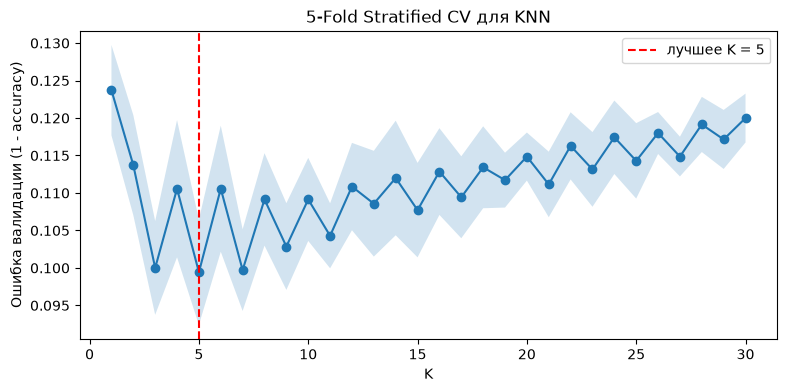

K             1       2       3       4       5       6       7       8   \
accuracy  0.8763  0.8863  0.9000  0.8894  0.9006  0.8894  0.9003  0.8909   
std       0.0060  0.0067  0.0063  0.0092  0.0070  0.0084  0.0055  0.0062   

K             9       10  ...      21      22      23      24      25      26  \
accuracy  0.8971  0.8909  ...  0.8889  0.8837  0.8869  0.8826  0.8857  0.8820   
std       0.0058  0.0055  ...  0.0044  0.0045  0.0050  0.0049  0.0050  0.0028   

K             27      28      29      30  
accuracy  0.8851  0.8809  0.8829  0.8800  
std       0.0026  0.0037  0.0039  0.0033  

[2 rows x 30 columns]
Оптимальное K: 5 (accuracy = 0.9006)


In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ks = range(1, 31)
means, stds = [], []
for k in ks:
    s = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_tr, y_tr, cv=skf, scoring="accuracy")
    means.append(s.mean()); stds.append(s.std())
means, stds = np.array(means), np.array(stds)
best_k = ks[int(np.argmax(means))]

err = 1 - means
plt.figure(figsize=(9, 4))
plt.plot(ks, err, marker="o")
plt.fill_between(ks, err - stds, err + stds, alpha=0.2)
plt.axvline(best_k, color="r", ls="--", label=f"лучшее K = {best_k}")
plt.xlabel("K"); plt.ylabel("Ошибка валидации (1 - accuracy)"); plt.legend()
plt.title("5-Fold Stratified CV для KNN")
plt.show()
print(pd.DataFrame({"K": ks, "accuracy": means.round(4), "std": stds.round(4)}).set_index("K").T)
print("Оптимальное K:", best_k, f"(accuracy = {means.max():.4f})")

При K=1 ошибка самая большая, модель переобучается. Дальше она падает, а примерно после K=10 потихоньку снова растёт, потому что соседей слишком много и модель всё чаще просто отвечает «не ушёл». Лучшее K вышло 5, accuracy около 0.90, хотя 3 и 7 почти такие же. Ещё заметил, что чётные K всегда чуть хуже соседних нечётных, наверное из-за ничьих при голосовании.

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

In [13]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

knn_best = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr, y_tr)
y_pred = knn_best.predict(X_te)

print("Доля класса «не ушёл»:", round(1 - y.mean(), 4))
print("Accuracy «глупой» модели, которая всегда отвечает «не ушёл»:", round((y_te == 0).mean(), 4))
print("Accuracy KNN:", round(accuracy_score(y_te, y_pred), 4))
print("\nМатрица ошибок:\n", confusion_matrix(y_te, y_pred))
print(classification_report(y_te, y_pred, target_names=["не ушёл", "ушёл"]))

Доля класса «не ушёл»: 0.8586
Accuracy «глупой» модели, которая всегда отвечает «не ушёл»: 0.8587
Accuracy KNN: 0.9

Матрица ошибок:
 [[1264   24]
 [ 126   86]]
              precision    recall  f1-score   support

     не ушёл       0.91      0.98      0.94      1288
        ушёл       0.78      0.41      0.53       212

    accuracy                           0.90      1500
   macro avg       0.85      0.69      0.74      1500
weighted avg       0.89      0.90      0.89      1500



Около 86% клиентов никуда не уходят. Значит, если модель всегда будет говорить «не ушёл», у неё уже будет accuracy 0.86, хотя она не найдёт ни одного уходящего клиента. У KNN 0.90, вроде нормально, но из 212 ушедших он нашёл только 86, recall 0.41. А компании нужны как раз те, кто уходит. Поэтому здесь важнее смотреть precision, recall и F1 по классу «ушёл», а не accuracy.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

In [14]:
from sklearn.metrics import f1_score

rng = np.random.default_rng(RANDOM_STATE)
noise_levels = [0.0, 0.05, 0.1, 0.2, 0.3]
rows = []
for noise in noise_levels:
    y_noisy = y_tr.copy()
    flip = rng.random(len(y_noisy)) < noise          # шум в метках
    y_noisy[flip] = 1 - y_noisy[flip]
    X_noisy = X_tr + rng.normal(0, noise / 2, X_tr.shape)  # шум в признаках
    for w in ["uniform", "distance"]:
        m = KNeighborsClassifier(n_neighbors=best_k, weights=w).fit(X_noisy, y_noisy)
        rows.append({"шум": noise, "weights": w,
                     "accuracy": accuracy_score(y_te, m.predict(X_te)),
                     "F1 (ушёл)": f1_score(y_te, m.predict(X_te))})
res = pd.DataFrame(rows).pivot(index="шум", columns="weights", values=["accuracy", "F1 (ушёл)"]).round(4)
res

accuracy         F1 (ушёл)        
weights distance uniform  distance uniform
шум                                       
0.00      0.8993  0.9000    0.5325  0.5342
0.05      0.9053  0.9060    0.5617  0.5635
0.10      0.8787  0.8787    0.4518  0.4518
0.20      0.8187  0.8187    0.2917  0.2917
0.30      0.7700  0.7700    0.3058  0.3058

In [15]:
# Целенаправленный шум: рядом с каждой тестовой точкой кладём одну «ложную» обучающую точку с противоположной меткой
rows = []
for eps in [0.001, 0.01, 0.05, 0.1]:
    fake_X = X_te.to_numpy() + rng.normal(0, eps, X_te.shape)
    X_aug = np.vstack([X_tr.to_numpy(), fake_X]); y_aug = np.concatenate([y_tr, 1 - y_te])
    for w in ["uniform", "distance"]:
        m = KNeighborsClassifier(n_neighbors=best_k, weights=w).fit(X_aug, y_aug)
        rows.append({"расстояние до выброса": eps, "weights": w, "accuracy": accuracy_score(y_te, m.predict(X_te))})
pd.DataFrame(rows).pivot(index="расстояние до выброса", columns="weights", values="accuracy").round(4)

weights,distance,uniform
расстояние до выброса,,
0.001,0.0000,0.5773
0.010,0.0027,0.5847
0.050,0.7053,0.7600
0.100,0.8813,0.8820


В первом эксперименте шум случайный, и оба варианта портятся почти одинаково, разницы особо не видно. Поэтому сделал второй: возле каждой тестовой точки положил одну обучающую точку с неправильной меткой. И вот тут разница огромная. С uniform этот выброс всего один голос из пяти, accuracy держится около 0.58. А с distance близкий выброс забирает почти весь вес, и accuracy падает почти до нуля. Так что distance гораздо сильнее боится выбросов рядом с точкой, он по сути начинает работать как K=1.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

+   0 шумовых признаков: F1 (ушёл) = 0.5429
+  10 шумовых признаков: F1 (ушёл) = 0.2369
+  50 шумовых признаков: F1 (ушёл) = 0.1289
+ 100 шумовых признаков: F1 (ушёл) = 0.0752


+ 300 шумовых признаков: F1 (ушёл) = 0.0756


+1000 шумовых признаков: F1 (ушёл) = 0.0690


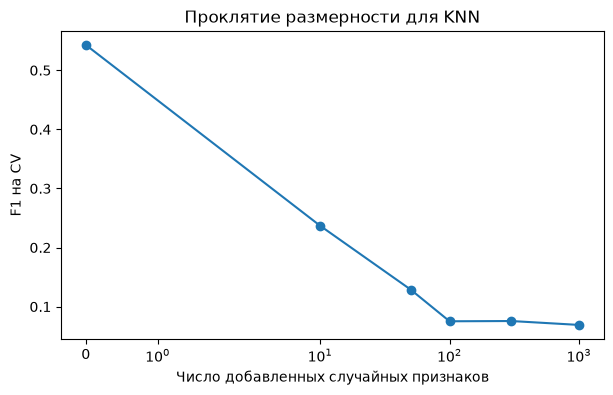

dim=    2: (max - min) / min расстояния = 31.178
dim=   10: (max - min) / min расстояния = 2.691
dim=  100: (max - min) / min расстояния = 0.438
dim= 1000: (max - min) / min расстояния = 0.097


In [16]:
rng = np.random.default_rng(RANDOM_STATE)
extra = [0, 10, 50, 100, 300, 1000]
scores = []
for n in extra:
    Xn = np.hstack([X.to_numpy(), rng.random((len(X), n))])
    s = cross_val_score(KNeighborsClassifier(n_neighbors=best_k), Xn, y, cv=skf, scoring="f1")
    scores.append(s.mean())
    print(f"+{n:4d} шумовых признаков: F1 (ушёл) = {s.mean():.4f}")

plt.figure(figsize=(7, 4))
plt.plot(extra, scores, marker="o"); plt.xscale("symlog")
plt.xlabel("Число добавленных случайных признаков"); plt.ylabel("F1 на CV")
plt.title("Проклятие размерности для KNN"); plt.show()

# Расстояния становятся почти одинаковыми
for dim in [2, 10, 100, 1000]:
    P = rng.random((500, dim)); d = np.linalg.norm(P[1:] - P[0], axis=1)
    print(f"dim={dim:5d}: (max - min) / min расстояния = {(d.max() - d.min()) / d.min():.3f}")

Хватило 10 случайных столбцов, чтобы F1 упал с 0.54 до 0.24, а после 100 модель почти перестаёт находить ушедших. Случайные признаки влияют на расстояние так же, как полезные, и соседи подбираются почти наугад. Последний вывод показывает, почему так: чем больше измерений, тем меньше разница между самой близкой и самой дальней точкой, при 1000 измерениях всего около 10%, то есть все точки оказываются почти на одном расстоянии.

### Упражнение 11: KNN для регрессии против классификации
Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE — Mean Squared Error) для различных значений K.

K       1      3       5       10      20      50      100
MSE  3.4375  2.428  2.2796  2.2931  2.8687  4.3194  6.2354


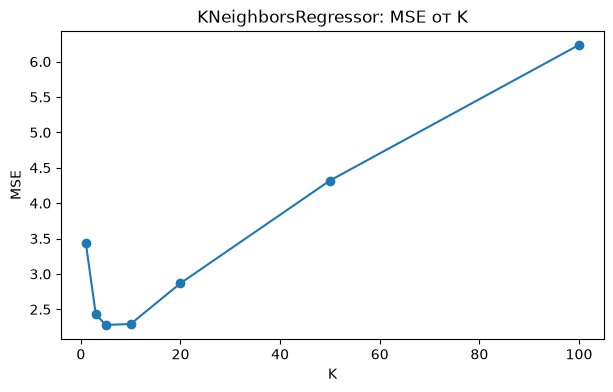

In [17]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

reg_X = raw[["total_day_minutes", "total_day_calls", "total_eve_minutes", "total_eve_calls"]]
reg_y = raw["total_day_charge"]
rX_tr, rX_te, ry_tr, ry_te = train_test_split(reg_X, reg_y, test_size=0.3, random_state=RANDOM_STATE)
scaler = MinMaxScaler().fit(rX_tr)
rX_tr_s, rX_te_s = scaler.transform(rX_tr), scaler.transform(rX_te)

ks_reg = [1, 3, 5, 10, 20, 50, 100]
mse = []
for k in ks_reg:
    r = KNeighborsRegressor(n_neighbors=k).fit(rX_tr_s, ry_tr)
    mse.append(mean_squared_error(ry_te, r.predict(rX_te_s)))
print(pd.Series(mse, index=pd.Index(ks_reg, name="K"), name="MSE").round(4).to_frame().T)

plt.figure(figsize=(7, 4)); plt.plot(ks_reg, mse, marker="o")
plt.xlabel("K"); plt.ylabel("MSE"); plt.title("KNeighborsRegressor: MSE от K"); plt.show()

В регрессии KNN не голосует, а просто берёт среднее у K соседей. total_day_charge почти линейно зависит от total_day_minutes, поэтому ошибка и так небольшая. При K=1 MSE 3.4, модель повторяет шум одного соседа, лучше всего вышло при K=5–10, около 2.3, а дальше снова хуже, при K=100 уже 6.2, потому что усредняется слишком много соседей.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif

X_tr_raw, X_te_raw, y_tr_raw, y_te_raw = train_test_split(
    X_raw, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

pipe = Pipeline([
    ("scaler", MinMaxScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("knn", KNeighborsClassifier()),
])
param_grid = {
    "select__k": [8, 12, "all"],
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}
grid = GridSearchCV(pipe, param_grid, cv=skf, scoring="f1", n_jobs=-1)
grid.fit(X_tr_raw, y_tr_raw)

print("Лучшие гиперпараметры:", grid.best_params_)
print("F1 на CV:", round(grid.best_score_, 4))
y_hat = grid.predict(X_te_raw)
print("Тестовая выборка: accuracy =", round(accuracy_score(y_te_raw, y_hat), 4),
      " F1 (ушёл) =", round(f1_score(y_te_raw, y_hat), 4))
print(classification_report(y_te_raw, y_hat, target_names=["не ушёл", "ушёл"]))

Лучшие гиперпараметры: {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform', 'select__k': 12}
F1 на CV: 0.6131
Тестовая выборка: accuracy = 0.9173  F1 (ушёл) = 0.6395
              precision    recall  f1-score   support

     не ушёл       0.93      0.98      0.95      1288
        ушёл       0.83      0.52      0.64       212

    accuracy                           0.92      1500
   macro avg       0.88      0.75      0.80      1500
weighted avg       0.91      0.92      0.91      1500



GridSearch выбрал K=3, p=1 (манхэттенское расстояние), обычные веса и 12 признаков из 16. На тесте F1 по ушедшим 0.64 и recall 0.52, это заметно лучше, чем было в восьмом упражнении. Скейлер я поставил внутрь пайплайна, чтобы он учился только на обучающих фолдах и в кросс-валидацию не попадала информация из валидации. А подбирал по F1, а не по accuracy, из-за того же дисбаланса классов.